# TPE を自分で書く（40 行）

**出典**　機械学習 4 分野の教科書 — 第 5 章 1-D 探索の自動化とモデル選定 ／ 05 履歴を使う探索——TPE は何をしているのか

**このノートのパス**　`ml-code/05_hpo/05_pure_tpe.ipynb`

**このノートで確かめること**
試行を**良い群と残り**に分け、それぞれに分布を当て、**比 l(x)/g(x) が最大の点**を次に選ぶ。
この 3 ステップをそのままコードにして、ランダム探索との違いを 1 次元で可視化する。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `numpy matplotlib` |
| 実行時間の目安 | 約 20 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q numpy matplotlib

In [3]:
import numpy as np

GAMMA, N_STARTUP, N_EI = 0.25, 10, 24    # 上位割合 / 立ち上がり試行 / 候補数

# rng は numpy の乱数生成器を渡す
#   rng = np.random.default_rng(SEED)

def _kde_sample(vals, lo, hi, rng, n):
    """良い群の値そのものを中心に置く簡易カーネル密度（Parzen 推定）"""
    vals = np.asarray(vals, dtype=float)
    bw   = max((hi - lo) * 0.15, 1e-9)   # 帯域幅。本家は近傍間隔から適応的に決める
    c    = rng.choice(vals, size=n)      # どの山から引くかを選ぶ
    return np.clip(rng.normal(c, bw, size=n), lo, hi)


def _logpdf(x, vals, lo, hi):
    vals = np.asarray(vals, dtype=float)
    bw   = max((hi - lo) * 0.15, 1e-9)
    z    = (x[:, None] - vals[None, :]) / bw
    p    = np.exp(-0.5 * z**2).sum(axis=1) / (len(vals) * bw * np.sqrt(2 * np.pi))
    return np.log(p + 1e-12)


def tpe_suggest(history, name, lo, hi, rng, log=False):
    """history から 1 つのパラメータの次の値を提案する"""
    if len(history) < N_STARTUP:                       # ① 立ち上がりはランダム
        u = rng.uniform(np.log(lo), np.log(hi)) if log else rng.uniform(lo, hi)
        return float(np.exp(u)) if log else float(u)

    L, H = (np.log(lo), np.log(hi)) if log else (lo, hi)
    xs = np.array([(np.log(h[name]) if log else h[name]) for h in history])
    ys = np.array([h["score"] for h in history])

    k    = max(int(np.ceil(GAMMA * len(ys))), 1)       # ② γ 分位で 2 群に割る
    good = xs[np.argsort(-ys)[:k]]                     #    良い群（スコア降順）
    bad  = xs[np.argsort(-ys)[k:]]

    cand  = _kde_sample(good, L, H, rng, N_EI)         # ③ 良い群の分布から候補を引き
    score = _logpdf(cand, good, L, H) - _logpdf(cand, bad, L, H)   # l(x)/g(x) 最大
    x = float(cand[int(np.argmax(score))])
    return float(np.exp(x)) if log else x

## 1 次元のテスト関数で、ランダム探索と比べる

最適解が x=0.75 付近にある山を探させる。**学習を挟まないので一瞬で終わる。**

In [4]:
def toy(x):
    """最大値が x≈0.75 にある 1 次元のテスト関数"""
    return np.exp(-((x - 0.75) ** 2) / 0.01) + 0.3 * np.exp(-((x - 0.2) ** 2) / 0.05)


def run(method, n_trials=60, seed=0):
    rng = np.random.default_rng(seed)
    hist = []
    for _ in range(n_trials):
        if method == "random":
            x = float(rng.uniform(0.0, 1.0))
        else:
            x = tpe_suggest(hist, "x", 0.0, 1.0, rng)
        hist.append({"x": x, "score": toy(x)})
    return hist


for m in ["random", "tpe"]:
    hs = [run(m, seed=s) for s in range(20)]           # 20 回まわして平均を取る
    best = np.mean([max(h["score"] for h in hh) for hh in hs])
    print(f"{m:>7}: 60 試行での最良スコア平均 = {best:.4f}")

 random: 60 試行での最良スコア平均 = 0.9843
    tpe: 60 試行での最良スコア平均 = 0.9644


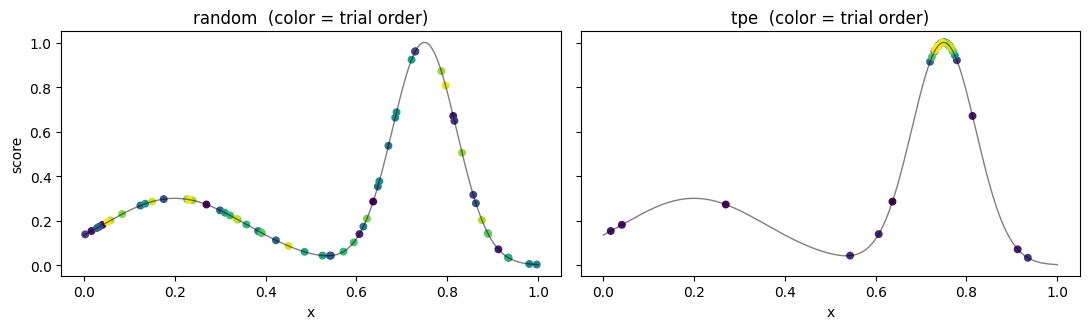

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
xs = np.linspace(0, 1, 500)
for ax, m in zip(axes, ["random", "tpe"]):
    h = run(m, n_trials=60, seed=0)
    ax.plot(xs, toy(xs), "k-", lw=1, alpha=.5)
    ax.scatter([d["x"] for d in h], [d["score"] for d in h],
               c=range(len(h)), cmap="viridis", s=22)
    ax.set_title(f"{m}  (color = trial order)"); ax.set_xlabel("x")
axes[0].set_ylabel("score")
plt.tight_layout(); plt.show()

## 読み取りどころ

**TPE の点は試行が進むほど山の周りに集まる**（色の明るい点が右の山に寄る）。ランダム探索は最後まで一様に散らばったままである。

⚠️ **この 40 行は本家 TPE の骨格であって本家ではない。**省いているもの——
① 帯域幅の適応（ここでは範囲の 15% 固定）② 多変量の相関（`multivariate=True` 相当）
③ 整数・カテゴリの専用処理 ④ 並列時の重複回避（`constant_liar`）⑤ 多目的最適化

**「仕組みを理解するための実装」と「本番で使う実装」は別物である。**理解したうえで本家を使うのが、いちばん速い。